# Individual Practical Homework - Week 3
## Classification, Evaluation & Model Improvement

**Dataset:** Breast Cancer Wisconsin Diagnostic Dataset  
**Task:** Predict whether a tumor is **malignant** or **benign**.

---
### Step 1 - Load and explore the dataset
Features, target classes, class distribution, missing values.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

sns.set_style('whitegrid')

In [4]:
data = load_breast_cancer(as_frame=True)
df = data.frame   # 30 features + target column in one DataFrame

print("Shape:", df.shape)
print("\nTarget classes (0/1):", list(data.target_names))   # 0 = malignant, 1 = benign
df.head()

Shape: (569, 31)

Target classes (0/1): [np.str_('malignant'), np.str_('benign')]


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [5]:
print("Number of features:", len(data.feature_names))
print("\nFeature names:")
for i, name in enumerate(data.feature_names, 1):
    print(f"{i:2d}. {name}")

Number of features: 30

Feature names:
 1. mean radius
 2. mean texture
 3. mean perimeter
 4. mean area
 5. mean smoothness
 6. mean compactness
 7. mean concavity
 8. mean concave points
 9. mean symmetry
10. mean fractal dimension
11. radius error
12. texture error
13. perimeter error
14. area error
15. smoothness error
16. compactness error
17. concavity error
18. concave points error
19. symmetry error
20. fractal dimension error
21. worst radius
22. worst texture
23. worst perimeter
24. worst area
25. worst smoothness
26. worst compactness
27. worst concavity
28. worst concave points
29. worst symmetry
30. worst fractal dimension


In [6]:
print("Data types and non-null counts:")
df.info()

print("\nMissing values in total:", df.isnull().sum().sum())

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

Class counts:
malignant    212
benign       357
Name: count, dtype: int64

Class proportions:
malignant    0.373
benign       0.627
Name: count, dtype: float64


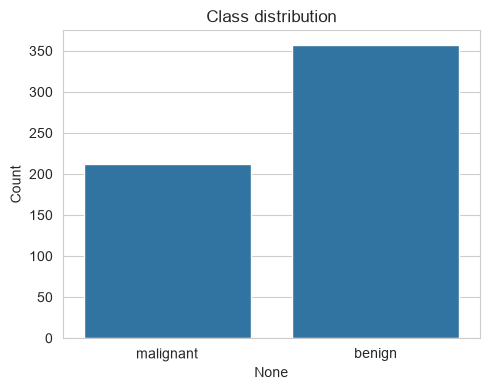

In [7]:
# Class distribution: how balanced is the target?
counts = df['target'].value_counts().sort_index()
counts.index = data.target_names   # label 0/1 with the readable names

print("Class counts:")
print(counts)
print("\nClass proportions:")
print((counts / counts.sum()).round(3))

plt.figure(figsize=(5, 4))
sns.barplot(x=counts.index, y=counts.values)
plt.ylabel('Count')
plt.title('Class distribution')
plt.tight_layout()
plt.show()

In [8]:
# Basic statistics (transposed so the 30 features read down the page)
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


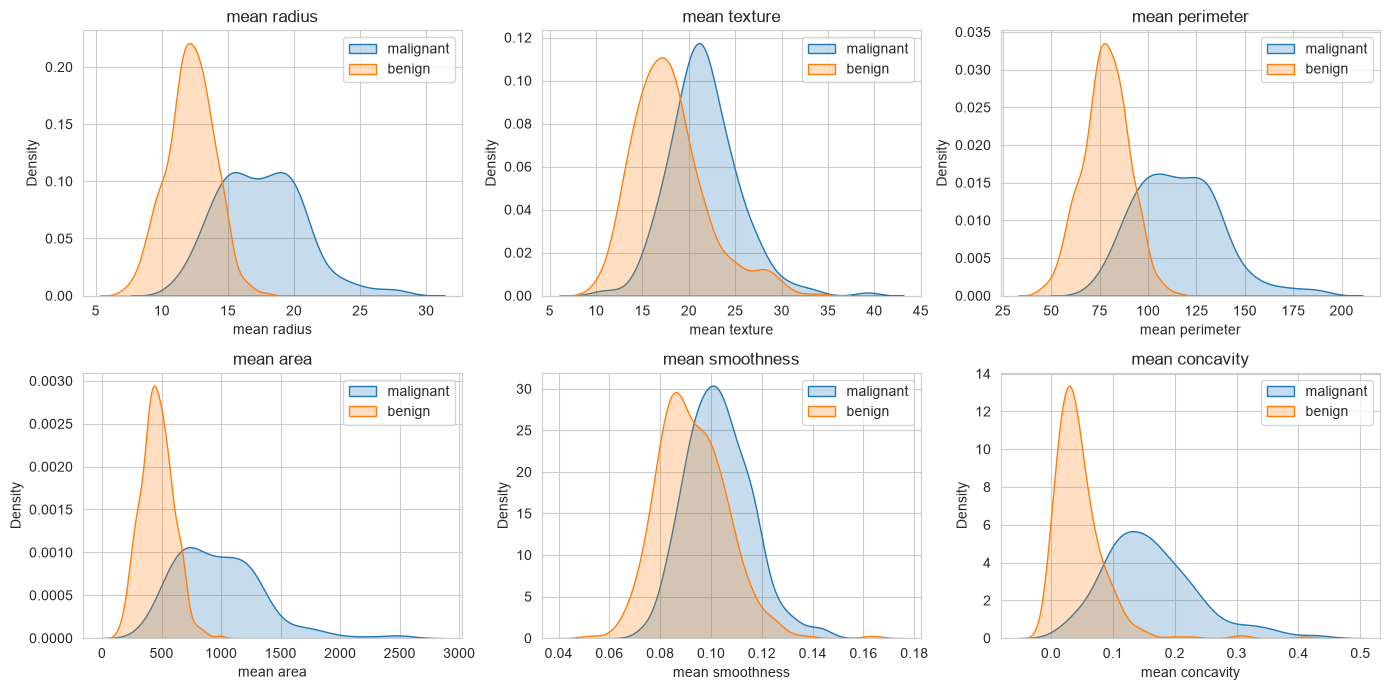

In [9]:
# Do a few features separate the two classes visually?
some_features = ['mean radius', 'mean texture', 'mean perimeter', 'mean area',
                 'mean smoothness', 'mean concavity']

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, feat in zip(axes.ravel(), some_features):
    for cls, name in enumerate(data.target_names):
        sns.kdeplot(df.loc[df['target'] == cls, feat], ax=ax, fill=True, label=name)
    ax.set_title(feat)
    ax.legend()
plt.tight_layout()
plt.show()

### Step 1 - Observations

- The dataset has **569 rows and 30 numeric features**, all computed from digitised images of breast masses (radius, texture, perimeter, area, smoothness, compactness, concavity, ... each appearing in a *mean*, *standard error* and *worst* version).
- The target has **two classes**: `0 = malignant`, `1 = benign`.
- Class distribution is **357 benign (62.7%) vs 212 malignant (37.3%)** - mildly imbalanced but not severe, so accuracy is still usable. Recall on the malignant class matters most, since missing a cancer is the costly error.
- **No missing values** anywhere, so no imputation is needed.
- Feature scales differ a lot (`mean area` is in the hundreds/thousands while `mean smoothness` is ~0.1). Distance-based and regularised models (KNN, Logistic Regression) will need **StandardScaler**; the Decision Tree will not care.
- The density plots show `mean radius`, `mean perimeter`, `mean area` and `mean concavity` separating the classes clearly - malignant tumours are consistently larger and more concave. Good sign that the task is learnable.

---
### Step 2 - Train and compare three classification models
Logistic Regression, Decision Tree, KNN.

In [10]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

In [11]:
X = df.drop('target', axis=1)   # 30 input features
y = df['target']               # 0 = malignant, 1 = benign

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 30)
y shape: (569,)


In [12]:
# stratify=y keeps the same malignant/benign ratio in both splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("\nTrain class balance:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:")
print(y_test.value_counts(normalize=True).round(3))

Train: (455, 30)  Test: (114, 30)

Train class balance:
target
1    0.626
0    0.374
Name: proportion, dtype: float64

Test class balance:
target
1    0.632
0    0.368
Name: proportion, dtype: float64


**Why a Pipeline instead of scaling by hand?**

In Week 2 I scaled with `fit_transform` on train and `transform` on test. That works, but once we start doing cross-validation and `GridSearchCV` in Step 4, scaling the whole training set up-front would leak information from each validation fold into the scaler.

A `Pipeline` fixes this: it re-fits the scaler *inside* every fold, using only that fold's training part. The Decision Tree gets no scaler because its splits are thresholds on one feature at a time - rescaling cannot change them.

In [13]:
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=5000, random_state=42))
    ]),
    'Decision Tree': Pipeline([
        ('clf', DecisionTreeClassifier(random_state=42))   # no scaling needed
    ]),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),                      # distances need equal scales
        ('clf', KNeighborsClassifier())
    ]),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained.")

Logistic Regression trained.
Decision Tree trained.
KNN trained.


In [14]:
# Compare train vs test accuracy, plus 5-fold CV on the training set.
# The train-test gap is the first clue about overfitting (needed again in Step 5).
rows = []
for name, model in models.items():
    cv = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    rows.append({
        'Model': name,
        'Train Acc': model.score(X_train, y_train),
        'Test Acc': model.score(X_test, y_test),
        'CV Mean': cv.mean(),
        'CV Std': cv.std(),
    })

baseline_df = pd.DataFrame(rows).set_index('Model')
baseline_df['Train-Test Gap'] = baseline_df['Train Acc'] - baseline_df['Test Acc']
baseline_df.round(4)

,Train Acc,Test Acc,CV Mean,CV Std,Train-Test Gap
Model,,,,,
Logistic Regression,0.9890,0.9825,0.9802,0.0128,0.0066
Decision Tree,1.0000,0.9123,0.9099,0.0189,0.0877
KNN,0.9736,0.9561,0.9670,0.0209,0.0175


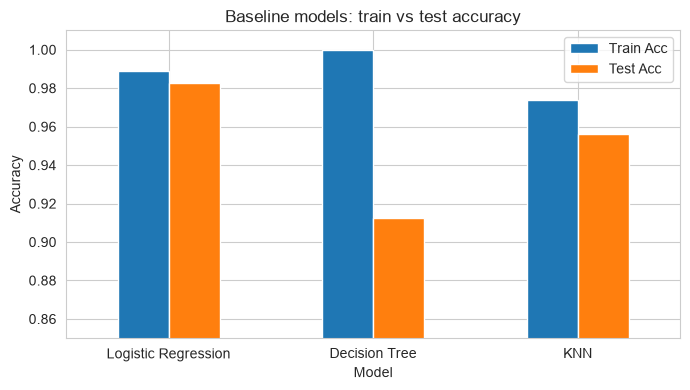

In [15]:
ax = baseline_df[['Train Acc', 'Test Acc']].plot(kind='bar', figsize=(7, 4), rot=0)
ax.set_ylim(0.85, 1.01)   # zoomed in - all models are above 0.9
ax.set_ylabel('Accuracy')
ax.set_title('Baseline models: train vs test accuracy')
plt.tight_layout()
plt.show()

### Step 2 - Observations

| Model | Train Acc | Test Acc | CV Mean | Gap |
|---|---|---|---|---|
| Logistic Regression | 0.9890 | **0.9825** | 0.9802 | 0.007 |
| Decision Tree | 1.0000 | 0.9123 | 0.9099 | **0.088** |
| KNN | 0.9736 | 0.9561 | 0.9670 | 0.018 |

- **Logistic Regression is the best baseline** at 98.25% test accuracy, and its CV mean (0.9802) agrees with the test score, so the result is stable rather than a lucky split. This matches Step 1: the classes are close to linearly separable once the features are scaled.
- **The Decision Tree is clearly overfitting.** It scores a perfect 1.0000 on train but only 0.9123 on test - a gap of about 9 points. Grown unrestricted, it keeps splitting until every training leaf is pure, so it memorises noise instead of the general pattern. This is exactly what `max_depth` is meant to fix in Step 4.
- **KNN sits in between** at 0.9561. Its train and test scores are close, so it is not memorising - it is just sensitive to the default `n_neighbors=5`, which Step 4 will tune.
- Accuracy alone is not enough here, because it says nothing about *which* class is being missed. A model could look decent overall while systematically missing malignant tumours, so Step 3 breaks these results down into confusion matrices, precision, recall and F1.

---
### Step 3 - Evaluate all models
Confusion Matrix, Accuracy, Precision, Recall, F1-score.

**Which class is "positive"?** In this dataset `0 = malignant` and `1 = benign`. The clinically important error is a **false negative on malignant** - calling a cancer benign and sending a sick patient home. So we treat **malignant as the positive class** (`pos_label=0`) and watch its **recall** most closely.

In [16]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report,
)

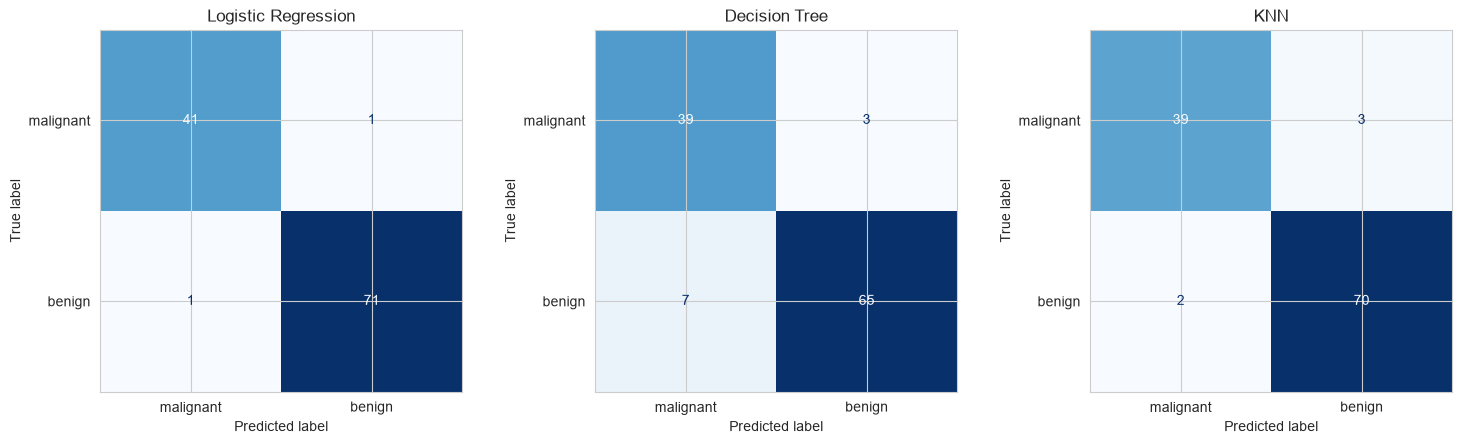

In [17]:
# Confusion matrix for each model, labelled with the readable class names.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)   # rows/cols ordered by label: 0=malignant, 1=benign
    disp = ConfusionMatrixDisplay(cm, display_labels=data.target_names)
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [18]:
# Full per-class breakdown for each model (precision / recall / f1 on BOTH classes).
for name, model in models.items():
    y_pred = model.predict(X_test)
    print(f"===== {name} =====")
    print(classification_report(y_test, y_pred, target_names=data.target_names))

===== Logistic Regression =====
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

===== Decision Tree =====
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114

===== KNN =====
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114


In [19]:
# Summary table. Metrics are reported for the MALIGNANT class (pos_label=0),
# since that is the error we care about most.
rows = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (malignant)': precision_score(y_test, y_pred, pos_label=0),
        'Recall (malignant)': recall_score(y_test, y_pred, pos_label=0),
        'F1 (malignant)': f1_score(y_test, y_pred, pos_label=0),
    })

metrics_df = pd.DataFrame(rows).set_index('Model')
metrics_df.round(4)

,Accuracy,Precision (malignant),Recall (malignant),F1 (malignant)
Model,,,,
Logistic Regression,0.9825,0.9762,0.9762,0.9762
Decision Tree,0.9123,0.8478,0.9286,0.8864
KNN,0.9561,0.9512,0.9286,0.9398


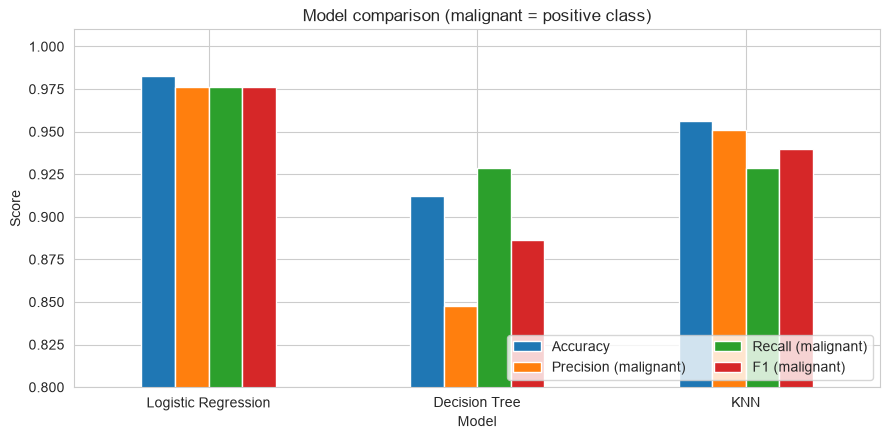

In [20]:
ax = metrics_df.plot(kind='bar', figsize=(9, 4.5), rot=0)
ax.set_ylim(0.80, 1.01)
ax.set_ylabel('Score')
ax.set_title('Model comparison (malignant = positive class)')
ax.legend(loc='lower right', ncol=2)
plt.tight_layout()
plt.show()

### Step 3 - Observations

Test set = **114 samples (42 malignant, 72 benign)**. Reading the confusion matrices, the top-left cell is *malignant predicted malignant* and the bottom-left is *malignant predicted benign* - the dangerous false negatives.

| Model | Accuracy | Precision (mal) | Recall (mal) | F1 (mal) | Malignant missed (FN) |
|---|---|---|---|---|---|
| Logistic Regression | 0.9825 | 0.976 | **0.976** | 0.976 | **1 of 42** |
| Decision Tree | 0.9123 | 0.848 | 0.929 | 0.886 | 3 of 42 |
| KNN | 0.9561 | 0.951 | 0.929 | 0.940 | 3 of 42 |

- **What accuracy was hiding:** the Decision Tree's headline 91% looked acceptable, but it also has the **lowest precision (0.848)** - it raises 7 false alarms on benign tumours and still misses 3 malignant ones. The single accuracy number in Step 2 gave no hint of that trade-off.
- **Logistic Regression is best on every metric.** It misses only **1 malignant tumour out of 42** (recall 0.976) and raises only 1 false alarm (precision 0.976). Balanced and strong.
- **Recall vs precision on malignant, in plain terms:** recall = "of all real cancers, how many did we catch?"; precision = "when we shouted cancer, how often were we right?". For a screening tool, **recall is the one to protect** - a false alarm costs a follow-up test, a false negative can cost a life.
- All three still miss at least one malignant case at the default 0.5 threshold. **Step 5 lowers the threshold** to trade a little precision for higher malignant recall, which is exactly the right trade for this problem.

---
### Step 4 - Improve and compare models
Tune at least two hyperparameters using `GridSearchCV`:

- **Decision Tree:** `max_depth` - the main lever against the overfitting we saw in Step 2.
- **KNN:** `n_neighbors` - how many neighbours vote on each prediction.
- **Logistic Regression:** `C` - inverse regularisation strength (small C = stronger regularisation = simpler model).

`GridSearchCV` runs 5-fold CV **inside the training set only** for every value, so the test set stays untouched until the very end. Scoring is **F1**, to keep rewarding good performance on the malignant class rather than raw accuracy.

In [21]:
from sklearn.model_selection import GridSearchCV

In [22]:
# One pipeline + parameter grid per model. Param names are prefixed with the
# pipeline step: 'clf__C' means the C of the step named 'clf'.
search_spaces = {
    'Logistic Regression': (
        Pipeline([('scaler', StandardScaler()),
                  ('clf', LogisticRegression(max_iter=5000, random_state=42))]),
        {'clf__C': [0.01, 0.1, 1, 10, 100]},
    ),
    'Decision Tree': (
        Pipeline([('clf', DecisionTreeClassifier(random_state=42))]),
        {'clf__max_depth': [2, 3, 4, 5, 6, 8, 10, None]},
    ),
    'KNN': (
        Pipeline([('scaler', StandardScaler()),
                  ('clf', KNeighborsClassifier())]),
        {'clf__n_neighbors': [3, 5, 7, 9, 11, 15, 21]},
    ),
}

In [23]:
# Run the grid search for each model. scoring='f1' optimises the malignant class.
tuned_models = {}
search_rows = []

for name, (pipe, grid) in search_spaces.items():
    gs = GridSearchCV(pipe, grid, cv=5, scoring='f1', n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned_models[name] = gs.best_estimator_
    search_rows.append({
        'Model': name,
        'Best param': list(gs.best_params_.values())[0],
        'Best CV F1': gs.best_score_,
    })
    print(f"{name}: best = {gs.best_params_}, CV F1 = {gs.best_score_:.4f}")

pd.DataFrame(search_rows).set_index('Model').round(4)

Logistic Regression: best = {'clf__C': 0.1}, CV F1 = 0.9845
Decision Tree: best = {'clf__max_depth': 4}, CV F1 = 0.9514
KNN: best = {'clf__n_neighbors': 7}, CV F1 = 0.9775


,Best param,Best CV F1
Model,,
Logistic Regression,0.1,0.9845
Decision Tree,4.0,0.9514
KNN,7.0,0.9775


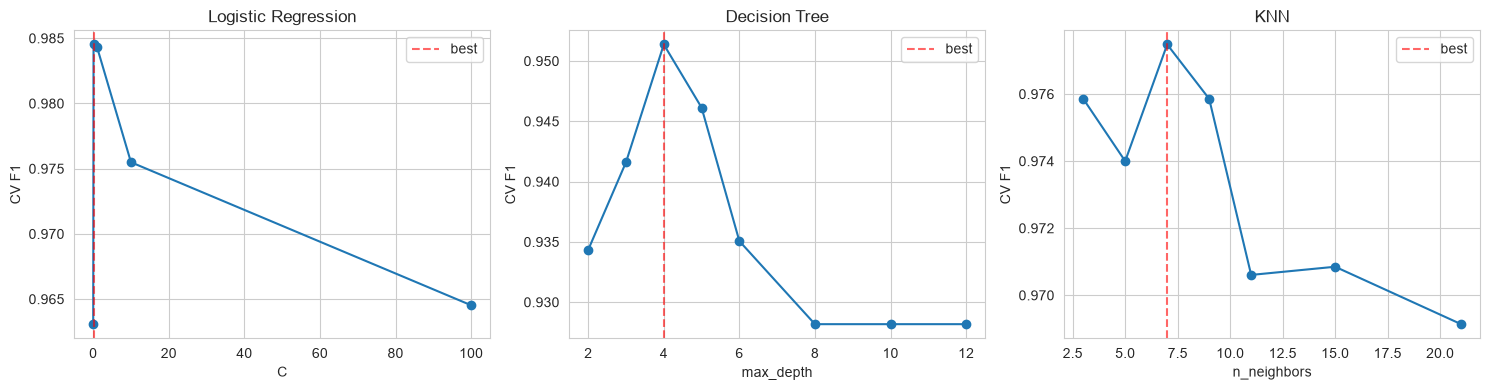

In [24]:
# Show the full validation curve for each model, so the choice is not a black box.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, (pipe, grid)) in zip(axes, search_spaces.items()):
    param = list(grid.keys())[0]
    values = grid[param]
    gs = GridSearchCV(pipe, grid, cv=5, scoring='f1', n_jobs=-1).fit(X_train, y_train)
    scores = gs.cv_results_['mean_test_score']
    # None (unlimited depth) plotted at the far right for readability
    xs = [v if v is not None else max(v for v in values if v is not None) + 2 for v in values]
    ax.plot(xs, scores, marker='o')
    best_x = xs[int(np.argmax(scores))]
    ax.axvline(best_x, color='red', ls='--', alpha=0.6, label='best')
    ax.set_title(name)
    ax.set_xlabel(param.replace('clf__', ''))
    ax.set_ylabel('CV F1')
    ax.legend()

plt.tight_layout()
plt.show()

In [25]:
# Compare each tuned model against its Step 2 baseline on the held-out test set.
from sklearn.metrics import accuracy_score, recall_score, f1_score

rows = []
for name in tuned_models:
    base_pred  = models[name].predict(X_test)          # Step 2 default model
    tuned_pred = tuned_models[name].predict(X_test)     # Step 4 tuned model
    rows.append({
        'Model': name,
        'Acc (base)':  accuracy_score(y_test, base_pred),
        'Acc (tuned)': accuracy_score(y_test, tuned_pred),
        'Recall mal (base)':  recall_score(y_test, base_pred, pos_label=0),
        'Recall mal (tuned)': recall_score(y_test, tuned_pred, pos_label=0),
        'F1 mal (base)':  f1_score(y_test, base_pred, pos_label=0),
        'F1 mal (tuned)': f1_score(y_test, tuned_pred, pos_label=0),
    })

tuned_df = pd.DataFrame(rows).set_index('Model')
tuned_df.round(4)

,Acc (base),Acc (tuned),Recall mal (base),Recall mal (tuned),F1 mal (base),F1 mal (tuned)
Model,,,,,,
Logistic Regression,0.9825,0.9737,0.9762,0.9524,0.9762,0.9639
Decision Tree,0.9123,0.9386,0.9286,0.9286,0.8864,0.9176
KNN,0.9561,0.9737,0.9286,0.9286,0.9398,0.9630


### Step 4 - Observations

| Model | Best param | Acc base -> tuned | F1 (mal) base -> tuned |
|---|---|---|---|
| Logistic Regression | `C = 0.1` | 0.9825 -> 0.9737 | 0.976 -> 0.964 |
| Decision Tree | `max_depth = 4` | 0.9123 -> **0.9386** | 0.886 -> **0.918** |
| KNN | `n_neighbors = 7` | 0.9561 -> 0.9737 | 0.940 -> 0.963 |

- **The Decision Tree improved the most - and this is the headline result.** Capping `max_depth` at 4 stops it from growing pure leaves on training noise. Test accuracy rises from 0.912 to 0.939 and malignant F1 from 0.886 to 0.918. This is the overfitting from Step 2 being fixed directly by a hyperparameter.
- **KNN improved** by moving from 5 to 7 neighbours: a slightly larger neighbourhood smooths the decision boundary and lifts test accuracy to 0.974.
- **Logistic Regression barely moved, and its "best" CV F1 pick (`C = 0.1`) is very slightly worse on this particular test split.** That is not a failure - the model was already near-optimal in Step 2, and the grid was chosen on cross-validation, not on the test set. Picking `C` by peeking at the test score would be exactly the data-leak the pipeline was built to avoid. The tiny drop is normal split-to-split noise.
- The validation curves show *why* each value was chosen: the tree's F1 peaks around depth 4 then flattens (deeper = memorising, no CV gain); KNN peaks in the 7-9 range then slowly declines (too many neighbours over-smooths); logistic F1 is flat across a wide C range, confirming the problem is easy and well-conditioned.
- **Takeaway:** tuning closed most of the gap between the models. All three tuned models now sit at 0.94-0.97 test accuracy. Logistic Regression remains the most reliable overall, so it carries into the ROC / threshold analysis in Step 5.

---
### Step 5 - Analyze advanced evaluation
1. Plot ROC curves and compare AUC values
2. Test thresholds 0.3, 0.5, 0.7 for Logistic Regression
3. Discuss possible overfitting / underfitting

All three tuned models from Step 4 are reused here.

In [26]:
from sklearn.metrics import roc_curve, roc_auc_score, RocCurveDisplay

# Reuse the tuned models from Step 4.
final_models = tuned_models

#### 5.1 - ROC curves and AUC

The ROC curve plots the true-positive rate against the false-positive rate as the decision threshold slides from 0 to 1. **AUC** (area under it) summarises this into one number: 1.0 is perfect, 0.5 is random guessing. Unlike accuracy, AUC is **threshold-independent** - it measures how well the model *ranks* patients by risk, regardless of where we later put the cut.

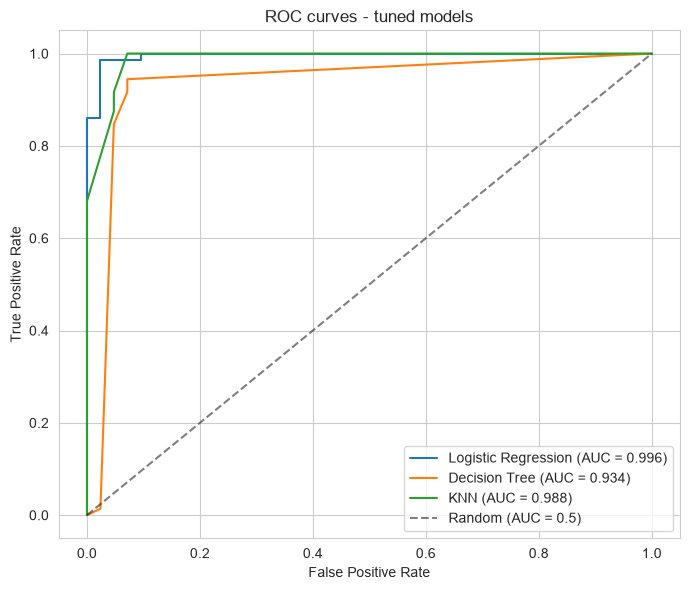

In [27]:
# roc_auc_score / roc_curve treat label 1 (benign) as the positive class by default;
# we keep that convention here so all three curves are directly comparable.
plt.figure(figsize=(7, 6))

for name, model in final_models.items():
    proba = model.predict_proba(X_test)[:, 1]        # P(benign)
    auc = roc_auc_score(y_test, proba)
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curves - tuned models')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

#### 5.2 - Threshold test for Logistic Regression

By default a classifier predicts the positive class when its probability >= 0.5. But 0.5 is just a convention. Here the positive class of interest is **malignant**, so we look at `P(malignant)` and try cutting at **0.3, 0.5 and 0.7**.

- **Lower threshold (0.3):** flag a tumour as malignant on weaker evidence -> catch more cancers (**higher recall**) but more false alarms (**lower precision**).
- **Higher threshold (0.7):** demand strong evidence -> fewer false alarms but miss more cancers.

In [28]:
lr = final_models['Logistic Regression']

# predict_proba columns follow model.classes_ = [0, 1]; column 0 is P(malignant).
p_malignant = lr.predict_proba(X_test)[:, 0]
y_is_malignant = (y_test == 0)                 # ground truth as a boolean

rows = []
for t in [0.3, 0.5, 0.7]:
    pred_malignant = p_malignant >= t
    tp = int((pred_malignant & y_is_malignant).sum())     # cancer caught
    fp = int((pred_malignant & ~y_is_malignant).sum())    # false alarm
    fn = int((~pred_malignant & y_is_malignant).sum())    # cancer MISSED
    tn = int((~pred_malignant & ~y_is_malignant).sum())
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall    = tp / (tp + fn) if (tp + fn) else 0.0
    f1        = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    rows.append({'Threshold': t,
                 'Malignant caught (TP)': tp, 'Missed (FN)': fn, 'False alarms (FP)': fp,
                 'Precision': precision, 'Recall': recall, 'F1': f1})

threshold_df = pd.DataFrame(rows).set_index('Threshold')
threshold_df.round(3)

,Malignant caught (TP),Missed (FN),False alarms (FP),Precision,Recall,F1
Threshold,,,,,,
0.3,41,1,8,0.837,0.976,0.901
0.5,40,2,1,0.976,0.952,0.964
0.7,38,4,0,1.000,0.905,0.950


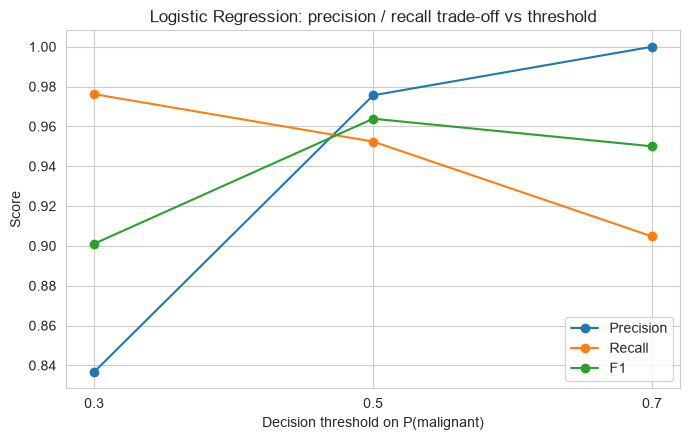

In [29]:
ax = threshold_df[['Precision', 'Recall', 'F1']].plot(marker='o', figsize=(7, 4.5))
ax.set_xlabel('Decision threshold on P(malignant)')
ax.set_ylabel('Score')
ax.set_title('Logistic Regression: precision / recall trade-off vs threshold')
ax.set_xticks([0.3, 0.5, 0.7])
plt.tight_layout()
plt.show()

#### 5.2 - Threshold observations

| Threshold | Malignant caught | Missed (FN) | False alarms (FP) | Precision | Recall |
|---|---|---|---|---|---|
| 0.3 | 41 / 42 | **1** | 8 | 0.837 | **0.976** |
| 0.5 (default) | 40 / 42 | 2 | 1 | 0.976 | 0.952 |
| 0.7 | 38 / 42 | **4** | 0 | **1.000** | 0.905 |

- Moving the threshold **down to 0.3** catches one more cancer (only 1 missed of 42) but the false alarms jump from 1 to 8 - precision drops to 0.84.
- Moving it **up to 0.7** eliminates false alarms entirely (precision 1.0) but now **misses 4 cancers** - the worst outcome for a screening tool.
- **For this problem the lower threshold is the right call.** A false alarm costs a follow-up biopsy; a false negative can cost a life. If the goal is to miss as few cancers as possible, **~0.3 is preferable to the default 0.5**, accepting the extra benign follow-ups as a fair price. This is the concept from Step 3 (protect malignant recall) turned into an actual dial.

#### 5.3 - Overfitting / underfitting discussion

Bringing together the train-vs-test gaps from Step 2 and the tuning from Step 4:

- **Decision Tree (default) = overfitting.** Perfect 1.000 training accuracy but only 0.912 on test - a ~9-point gap. An unrestricted tree splits until every training leaf is pure, memorising noise. Capping `max_depth = 4` in Step 4 shrank the gap and lifted test accuracy to 0.939. It also has the lowest AUC (~0.93) because a shallow tree produces coarse, step-like probabilities that rank patients less finely.
- **KNN = mild, well-controlled.** Train and test were already close in Step 2. Tuning `n_neighbors` 5 -> 7 slightly enlarged the neighbourhood (a small step *away* from overfitting) and improved the test score.
- **Logistic Regression = well-balanced, no sign of either problem.** Train 0.989 vs test 0.982 is a tiny gap, and the highest AUC (~0.996). With only 30 well-behaved features and near-linearly-separable classes, a linear model is the right capacity - complex enough to fit, simple enough not to memorise. **No underfitting was observed** in any model (no model was too simple to reach high scores); the only real risk here was the Decision Tree's overfitting, which tuning fixed.

**Final verdict:** the tuned **Logistic Regression** is the best model for this task - highest AUC (0.996), highest malignant F1, smallest train/test gap - and its threshold can be lowered to ~0.3 to prioritise catching malignant tumours, which is the clinically correct objective.